# titanic dataset py work krna h 

In [25]:
import pandas as pd 
import numpy as np 
import seaborn as sns
import matplotlib.pyplot as plt 
from sklearn import tree

from sklearn.model_selection import train_test_split
# Classification ke liye Decision Tree aur Metrics import karein
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [26]:
df = sns.load_dataset('titanic')
print("data shape", df.shape)
df.head()

data shape (891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [27]:
X = df[['pclass','sex', 'age', 'sibsp', 'parch','fare']]
y = df['survived']

In [28]:
# 3. 'sex' column ko 0 aur 1 mein convert karein (drop_first=True best practice hai)
X = pd.get_dummies(X, columns=['sex'], drop_first=True)

In [29]:
# 4. Missing values check karein
print("Missing values before filling:\n", X.isnull().sum())

Missing values before filling:
 pclass        0
age         177
sibsp         0
parch         0
fare          0
sex_male      0
dtype: int64


In [30]:
# 5. Missing values fill karein (Age aur Fare dono ko)
X['age'] = X['age'].fillna(X['age'].mean())
X['fare'] = X['fare'].fillna(X['fare'].mean()) 

In [31]:
# 6. Train-Test Split (Syntax fix kar diya)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Data split successfully!")
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

Data split successfully!
X_train shape: (712, 6)
X_test shape: (179, 6)


In [32]:
# Model Initialize Karein
model = DecisionTreeClassifier(random_state=42)

# Model Train Karein
model.fit(X_train, y_train)

# Predictions Karein
y_pred = model.predict(X_test)

In [33]:
# Model Evaluate Karein (Accuracy aur Report)

# 1. Accuracy Check karein
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy * 100:.2f}%\n")

# 2. Classification Report (Precision, Recall, F1-Score)
print("--- Classification Report ---")
print(classification_report(y_test, y_pred))

# 3. Confusion Matrix (Kitne log sahi predict hue, kitne ghalat)
print("--- Confusion Matrix ---")
print(confusion_matrix(y_test, y_pred))

Model Accuracy: 75.98%

--- Classification Report ---
              precision    recall  f1-score   support

           0       0.79      0.80      0.80       105
           1       0.71      0.70      0.71        74

    accuracy                           0.76       179
   macro avg       0.75      0.75      0.75       179
weighted avg       0.76      0.76      0.76       179

--- Confusion Matrix ---
[[84 21]
 [22 52]]


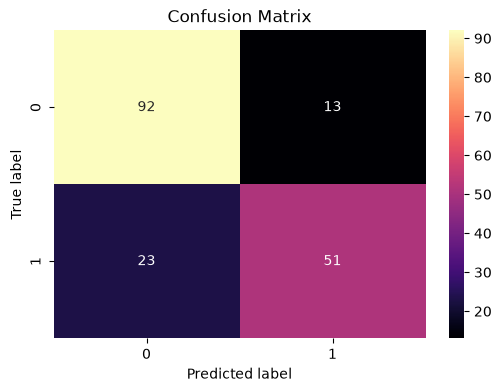

In [37]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Confusion Matrix calculate karein
cm = confusion_matrix(y_test, y_pred)

# 2. Graph (Heatmap) banayein
plt.figure(figsize=(6, 4))

# sns.heatmap graph draw karta hai
sns.heatmap(cm, annot=True, fmt='d', cmap='magma') 
# annot=True: Boxes ke andar numbers likhne ke liye
# fmt='d': Numbers ko integer (bina decimal) dikhane ke liye
# cmap='magma': Rangon ka style (Dark se Light)

# 3. Labels add karein
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.title('Confusion Matrix')

# 4. Graph show karein
plt.show()

Accuracy with Max Depth 3: 79.89%

Clean graph saved!


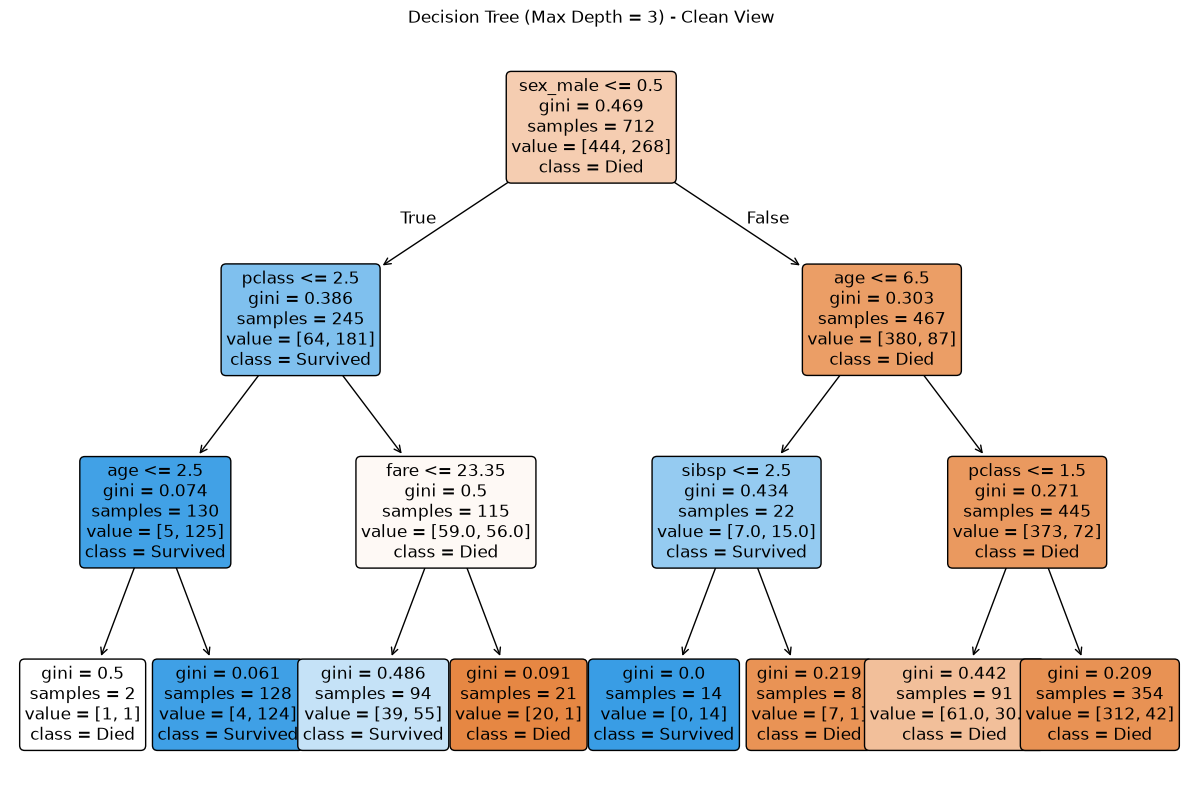

In [35]:
# 1. Model ko max_depth ke sath dobara banayein (3 ya 4 best hai)
model = DecisionTreeClassifier(max_depth=3, random_state=42)
model.fit(X_train, y_train)

# 2. Dobara predictions aur accuracy check karein
y_pred = model.predict(X_test)
print(f"Accuracy with Max Depth 3: {accuracy_score(y_test, y_pred) * 100:.2f}%\n")

# 3. Ab Clean Graph Plot karein
plt.figure(figsize=(15, 10)) # Figure ka size thora adjust kar lein

tree.plot_tree(model, 
               filled=True, 
               feature_names=X.columns, 
               class_names=['Died', 'Survived'],
               fontsize=12,        # Font size bara kar diya taake parha ja sake
               rounded=True)       # Boxes ko thora smooth banane ke liye

plt.title("Decision Tree (Max Depth = 3) - Clean View")

# 4. Save aur Show
plt.savefig("decision_tree_clean.pdf", format="pdf", dpi=300, bbox_inches='tight')
print("Clean graph saved!")
plt.show()

# KNN 

In [38]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

# 1. DATA SCALING (KNN ke liye bohat zaroori step)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 2. Model Initialize karein (n_neighbors=5 default hota hai, aap change kar sakte hain)
model1 = KNeighborsClassifier(n_neighbors=5)

# 3. Model Train karein (Scaled data use karein)
model1.fit(X_train_scaled, y_train)

# 4. Predictions lein (Scaled test data use karein)
y_pred = model1.predict(X_test_scaled)

# 5. Model Evaluate karein
print("--- KNN Model Results ---")
print(f"Accuracy: {accuracy_score(y_test, y_pred) * 100:.2f}%\n")

print("--- Confusion Matrix ---")
print(confusion_matrix(y_test, y_pred))

print("\n--- Classification Report ---")
print(classification_report(y_test, y_pred))

--- KNN Model Results ---
Accuracy: 78.21%

--- Confusion Matrix ---
[[86 19]
 [20 54]]

--- Classification Report ---
              precision    recall  f1-score   support

           0       0.81      0.82      0.82       105
           1       0.74      0.73      0.73        74

    accuracy                           0.78       179
   macro avg       0.78      0.77      0.77       179
weighted avg       0.78      0.78      0.78       179



# Random Forest

In [39]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# 1. Model Initialize karein
# n_estimators: Trees ki tadad (jitni zyada, utna behtar, lekin time zyada lega)
# random_state: Taake har baar same result aaye
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

# 2. Model Train karein
# ZAROORI NOTE: Random Forest ko Data Scaling (StandardScaler) ki zaroorat NAHI hoti!
# Isliye hum direct X_train aur y_train use kar rahe hain.
rf_model.fit(X_train, y_train)

# 3. Predictions lein
y_pred_rf = rf_model.predict(X_test)

# 4. Model Evaluate karein
print("--- Random Forest Results ---")
print(f"Accuracy: {accuracy_score(y_test, y_pred_rf) * 100:.2f}%\n")

print("--- Confusion Matrix ---")
print(confusion_matrix(y_test, y_pred_rf))

print("\n--- Classification Report ---")
print(classification_report(y_test, y_pred_rf))

--- Random Forest Results ---
Accuracy: 81.01%

--- Confusion Matrix ---
[[90 15]
 [19 55]]

--- Classification Report ---
              precision    recall  f1-score   support

           0       0.83      0.86      0.84       105
           1       0.79      0.74      0.76        74

    accuracy                           0.81       179
   macro avg       0.81      0.80      0.80       179
weighted avg       0.81      0.81      0.81       179



# Logistic Regression ye classification ki hi type h 

In [40]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# 1. DATA SCALING (Logistic Regression ke liye bohat zaroori)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 2. Model Initialize karein
# max_iter=1000: Model ko solve hone ka waqt dene ke liye (taake warning na aaye)
log_model = LogisticRegression(max_iter=1000, random_state=42)

# 3. Model Train karein (Scaled data use karein)
log_model.fit(X_train_scaled, y_train)

# 4. Predictions lein (Scaled test data use karein)
y_pred_log = log_model.predict(X_test_scaled)

# 5. Model Evaluate karein
print("--- Logistic Regression Results ---")
print(f"Accuracy: {accuracy_score(y_test, y_pred_log) * 100:.2f}%\n")

print("--- Confusion Matrix ---")
print(confusion_matrix(y_test, y_pred_log))

print("\n--- Classification Report ---")
print(classification_report(y_test, y_pred_log))

--- Logistic Regression Results ---
Accuracy: 79.89%

--- Confusion Matrix ---
[[90 15]
 [21 53]]

--- Classification Report ---
              precision    recall  f1-score   support

           0       0.81      0.86      0.83       105
           1       0.78      0.72      0.75        74

    accuracy                           0.80       179
   macro avg       0.80      0.79      0.79       179
weighted avg       0.80      0.80      0.80       179



# SVM - support vector machine
# Naive Bayes

In [41]:
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

# --- 5. SVM (Support Vector Machine) ---
# SVM ko bhi Scaling ki zaroorat hoti hai
svm_model = SVC(kernel='linear', random_state=42) # 'linear' ya 'rbf' use kar sakte hain
svm_model.fit(X_train_scaled, y_train) 
y_pred_svm = svm_model.predict(X_test_scaled)
print("SVM Accuracy:", accuracy_score(y_test, y_pred_svm) * 100)

# --- 6. Naive Bayes (Gaussian) ---
# Naive Bayes ko Scaling ki zaroorat NAHI hoti
nb_model = GaussianNB()
nb_model.fit(X_train, y_train)
y_pred_nb = nb_model.predict(X_test)
print("Naive Bayes Accuracy:", accuracy_score(y_test, y_pred_nb) * 100)

SVM Accuracy: 78.2122905027933
Naive Bayes Accuracy: 77.09497206703911


In [42]:
# Sab models ko ek dictionary mein dalein
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "SVM": SVC(kernel='linear', random_state=42),
    "Naive Bayes": GaussianNB()
}

# Scaling wale models ke liye alag se scaled data use karenge
# (Note: Tree based models scaling se affect nahi hote, par error nahi aayega)

results = {}

for name, model in models.items():
    # Tree based models ko bina scale kiye, baaki ko scale karke train karein
    if name in ["Decision Tree", "Random Forest", "Naive Bayes"]:
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
    else:
        model.fit(X_train_scaled, y_train)
        y_pred = model.predict(X_test_scaled)
        
    # Accuracy calculate karein
    acc = accuracy_score(y_test, y_pred) * 100
    results[name] = acc

# Results ko print karein
print("--- Model Comparison ---")
for name, acc in sorted(results.items(), key=lambda x: x[1], reverse=True):
    print(f"{name}: {acc:.2f}%")

--- Model Comparison ---
Random Forest: 81.01%
Logistic Regression: 79.89%
KNN: 78.21%
SVM: 78.21%
Naive Bayes: 77.09%
Decision Tree: 75.98%


# GridSearchCV

In [43]:
from sklearn.model_selection import GridSearchCV

param_grid_rf = {
    'n_estimators': [50, 100, 200],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5]
}

grid_rf = GridSearchCV(RandomForestClassifier(random_state=42), 
                       param_grid_rf, cv=5, n_jobs=-1)
grid_rf.fit(X_train, y_train)

print("Best Parameters:", grid_rf.best_params_)
print("Best Accuracy:", grid_rf.best_score_)

Best Parameters: {'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 100}
Best Accuracy: 0.8243967300305328
